In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import os
import numpy as np

# Gjejme skedaret e dataset-it ISS
for folder, subfolders, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(folder, file))


/kaggle/input/datasets/shqipezeneli/esa-programmable-cubes-iss-dataset/Initial_Config.npy
/kaggle/input/datasets/shqipezeneli/esa-programmable-cubes-iss-dataset/Initial_Cube_Types.npy
/kaggle/input/datasets/shqipezeneli/esa-programmable-cubes-iss-dataset/Target_Config.npy
/kaggle/input/datasets/shqipezeneli/esa-programmable-cubes-iss-dataset/Target_Cube_Types.npy


In [2]:

import numpy as np

# Folderi ku gjendet dataset-i ne Kaggle
dataset_path = "/kaggle/input/datasets/shqipezeneli/esa-programmable-cubes-iss-dataset/"

# Leximi i konfigurimit fillestar
initial_config = np.load(dataset_path + "Initial_Config.npy")

# Shfaqja e informacionit
print("Forma e dataset-it:", initial_config.shape)
print("Lloji i te dhenave:", initial_config.dtype)
print("5 elementet e para:")
print(initial_config[:5])


Forma e dataset-it: (148, 3)
Lloji i te dhenave: int64
5 elementet e para:
[[-1  3  0]
 [ 7  2  5]
 [ 9  5  5]
 [ 1  4  6]
 [ 4  5  5]]


In [3]:

# Leximi i te dhenave te skenarit ISS
initial_types = np.load(dataset_path + "Initial_Cube_Types.npy")
target_config = np.load(dataset_path + "Target_Config.npy")
target_types = np.load(dataset_path + "Target_Cube_Types.npy")

# Shfaqja e dimensioneve
print("Initial Config:", initial_config.shape)
print("Initial Cube Types:", initial_types.shape)
print("Target Config:", target_config.shape)
print("Target Cube Types:", target_types.shape)

# Kontrollimi i llojeve te kubeve
print("\nLlojet fillestare:", np.unique(initial_types))
print("Llojet e synuara:", np.unique(target_types))


Initial Config: (148, 3)
Initial Cube Types: (148,)
Target Config: (148, 3)
Target Cube Types: (148,)

Llojet fillestare: [0 1 2]
Llojet e synuara: [0 1 2]


In [4]:

# Numri i kubeve sipas llojit

print("KUBET NE KONFIGURIMIN FILLESTAR")
llojet, numrat = np.unique(initial_types, return_counts=True)

for lloji, numri in zip(llojet, numrat):
    print(f"Lloji {lloji}: {numri} kube")

print("\nKUBET NE KONFIGURIMIN PERFUNDIMTAR")
llojet, numrat = np.unique(target_types, return_counts=True)

for lloji, numri in zip(llojet, numrat):
    print(f"Lloji {lloji}: {numri} kube")


KUBET NE KONFIGURIMIN FILLESTAR
Lloji 0: 66 kube
Lloji 1: 22 kube
Lloji 2: 60 kube

KUBET NE KONFIGURIMIN PERFUNDIMTAR
Lloji 0: 66 kube
Lloji 1: 22 kube
Lloji 2: 60 kube


In [5]:

# Analiza e koordinatave te kubeve

print("KONFIGURIMI FILLESTAR")
print("Koordinatat minimale (X, Y, Z):", initial_config.min(axis=0))
print("Koordinatat maksimale (X, Y, Z):", initial_config.max(axis=0))

print("\nKONFIGURIMI PERFUNDIMTAR")
print("Koordinatat minimale (X, Y, Z):", target_config.min(axis=0))
print("Koordinatat maksimale (X, Y, Z):", target_config.max(axis=0))

# Kontrollojme nese ka pozicione te perseritura
print("\nPozicione unike ne fillim:",
      len(np.unique(initial_config, axis=0)))

print("Pozicione unike ne fund:",
      len(np.unique(target_config, axis=0)))


KONFIGURIMI FILLESTAR
Koordinatat minimale (X, Y, Z): [-1 -2 -2]
Koordinatat maksimale (X, Y, Z): [12  8  8]

KONFIGURIMI PERFUNDIMTAR
Koordinatat minimale (X, Y, Z): [0 2 0]
Koordinatat maksimale (X, Y, Z): [11  8  7]

Pozicione unike ne fillim: 148
Pozicione unike ne fund: 148


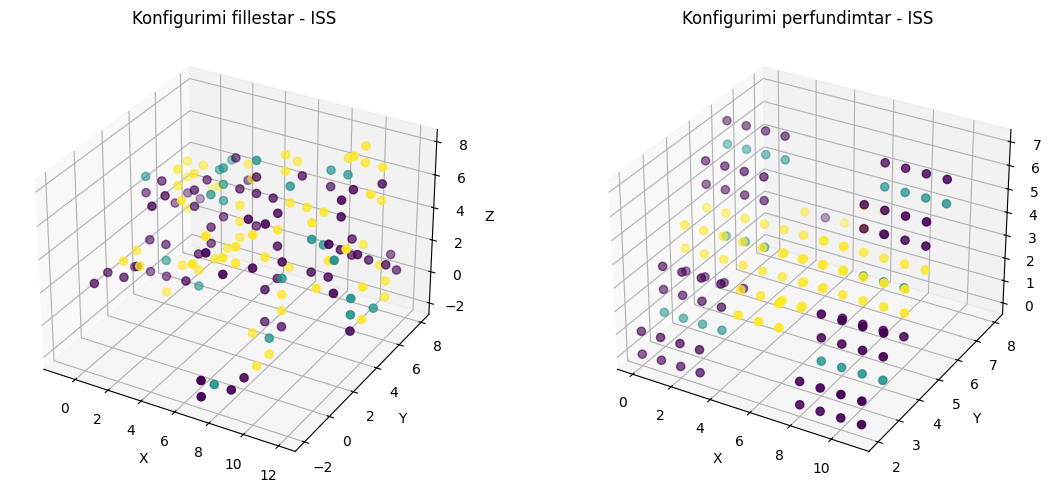

In [6]:

import matplotlib.pyplot as plt

# Krijimi i figures 3D
fig = plt.figure(figsize=(12, 5))

# Konfigurimi fillestar
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(
    initial_config[:, 0],
    initial_config[:, 1],
    initial_config[:, 2],
    c=initial_types,
    cmap='viridis',
    s=35
)
ax1.set_title("Konfigurimi fillestar - ISS")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.set_zlabel("Z")

# Konfigurimi perfundimtar
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(
    target_config[:, 0],
    target_config[:, 1],
    target_config[:, 2],
    c=target_types,
    cmap='viridis',
    s=35
)
ax2.set_title("Konfigurimi perfundimtar - ISS")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")

plt.tight_layout()
plt.show()


In [15]:

import os

# Kerkojme skedaret ZIP te simulimit ne Kaggle
for folder, subfolders, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith(".zip"):
            print("ZIP i gjetur:", os.path.join(folder, file))
print("Kontrollimi perfundoi!")

Kontrollimi perfundoi!


In [16]:

import os

# Gjejme vendndodhjen e kodit zyrtar te ESA-s
for folder, subfolders, files in os.walk("/kaggle/input"):
    if "programmable_cubes_UDP.py" in files:
        print("Folderi i simulimit:", folder)
        print("Skedaret:", files)


Folderi i simulimit: /kaggle/input/datasets/shqipezeneli/esa-programmable-cubes-simulation-files/ESA_Simulation_Files
Skedaret: ['CubeMoveset.py', 'programmable_cubes_UDP.py']


In [17]:

import os
import shutil

# Rruga ku gjenden skedaret e simulimit
simulation_path = (
    "/kaggle/input/datasets/shqipezeneli/"
    "esa-programmable-cubes-simulation-files/ESA_Simulation_Files"
)

# Folderi ku do ta pergatisim simulimin
work_path = "/kaggle/working/ESA_Simulation"

# Kopjojme skedaret e simulimit pa ndryshu origjinalet
shutil.copytree(
    simulation_path,
    work_path,
    dirs_exist_ok=True
)

# Krijojme folderin ku do te vendosen te dhenat ISS
iss_folder = os.path.join(work_path, "data", "ISS")
os.makedirs(iss_folder, exist_ok=True)

# Kopjojme kater skedaret e dataset-it ISS
for filename in [
    "Initial_Config.npy",
    "Initial_Cube_Types.npy",
    "Target_Config.npy",
    "Target_Cube_Types.npy"
]:
    shutil.copy2(
        os.path.join(dataset_path, filename),
        os.path.join(iss_folder, filename)
    )

# Kontrollojme nese gjithcka eshte kopjuar
print("Simulimi u pergatit me sukses!")
print("Folderi kryesor:", work_path)
print("Skedaret ISS:", os.listdir(iss_folder))


Simulimi u pergatit me sukses!
Folderi kryesor: /kaggle/working/ESA_Simulation
Skedaret ISS: ['Initial_Config.npy', 'Target_Config.npy', 'Initial_Cube_Types.npy', 'Target_Cube_Types.npy']


In [18]:

import os
import sys

# Kalojme ne folderin e simulimit
os.chdir("/kaggle/working/ESA_Simulation")

# Shtojme folderin ne listen e moduleve Python
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Importojme klasen zyrtare te ESA-s
from programmable_cubes_UDP import programmable_cubes_UDP

# Krijojme problemin ISS
udp = programmable_cubes_UDP("ISS")

print("Problemi ISS u inicializua me sukses!")
print("Numri i kubeve:", udp.setup["num_cubes"])
print("Numri maksimal i komandave:", udp.setup["max_cmds"])


Problemi ISS u inicializua me sukses!
Numri i kubeve: 148
Numri maksimal i komandave: 6000


In [20]:


import numpy as np

# Testimi i funksionit fitness te ESA-s

# Krijojme kromozomin pa levizje
chromosome = np.array([-1], dtype=np.int64)

# Llogarisim fitness fillestar
rezultati = udp.fitness(chromosome)

print("Fitness fillestar:", rezultati)
print("Numri i komandave te kryera: 0")



Fitness fillestar: [np.float64(-0.0)]
Numri i komandave te kryera: 0


In [21]:

import numpy as np

# Testojme nje komande levizjeje per kubin 0
# 0 i pare = ID e kubit
# 0 i dyte = komanda e rrotullimit
# -1 = fundi i sekuences

chromosome_test = np.array([0, 0, -1], dtype=np.int64)

# Kontrollojme levizjen me simulatorin e ESA-s
udp.pretty(chromosome_test)

# Shfaqim rezultatin fitness
rezultati_test = udp.fitness(chromosome_test)

print("Fitness pas komandes:", rezultati_test)


Fitness pas komandes: [np.float64(-0.007914756025867095)]


In [22]:

import numpy as np

# Marrim konfigurimin fillestar
pozicionet_fillestare = initial_config.copy()

# Ekzekutojme komanden dhe marrim konfigurimin e ri
udp.fitness(chromosome_test)
pozicionet_reja = udp.final_cube_positions.copy()

# Gjejme cilat kube kane ndryshu pozicion
kubet_e_levizura = np.where(
    np.any(pozicionet_fillestare != pozicionet_reja, axis=1)
)[0]

print("Numri i kubeve qe kane levize:", len(kubet_e_levizura))
print("ID e kubeve te levizura:", kubet_e_levizura)

for kubi in kubet_e_levizura:
    print("Kubi:", kubi)
    print("Pozicioni fillestar:", pozicionet_fillestare[kubi])
    print("Pozicioni i ri:", pozicionet_reja[kubi])


Numri i kubeve qe kane levize: 1
ID e kubeve te levizura: [0]
Kubi: 0
Pozicioni fillestar: [-1  3  0]
Pozicioni i ri: [0 2 0]


In [23]:

import numpy as np

# Kerkojme levizjet e vlefshme per 10 kubet e para

levizjet_e_vlefshme = []

for cube_id in range(10):
    for command_id in range(6):

        # Krijojme komanden per nje kub
        chromosome = np.array(
            [cube_id, command_id, -1],
            dtype=np.int64
        )

        # Ekzekutojme komanden
        udp.fitness(chromosome)

        # Kontrollojme a ka ndryshu pozicioni i kubit
        pozicioni_i_ri = udp.final_cube_positions[cube_id]

        if not np.array_equal(
            initial_config[cube_id],
            pozicioni_i_ri
        ):
            levizjet_e_vlefshme.append(
                (cube_id, command_id)
            )

print("Numri i levizjeve te vlefshme:", len(levizjet_e_vlefshme))
print("Levizjet e vlefshme:", levizjet_e_vlefshme)


Numri i levizjeve te vlefshme: 20
Levizjet e vlefshme: [(0, 0), (0, 1), (0, 4), (1, 0), (1, 1), (1, 3), (3, 0), (3, 1), (3, 2), (3, 4), (3, 5), (6, 1), (6, 2), (6, 3), (7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5)]


In [24]:

import numpy as np

# Ruajme rezultatet e te gjitha levizjeve
rezultatet = []

for cube_id, command_id in levizjet_e_vlefshme:

    chromosome = np.array(
        [cube_id, command_id, -1],
        dtype=np.int64
    )

    # Llogarisim fitness per secilen levizje
    fitness = float(udp.fitness(chromosome)[0])

    rezultatet.append(
        (cube_id, command_id, fitness)
    )

# Rendisim rezultatet nga fitness me i mire
rezultatet.sort(key=lambda x: x[2])

print("5 levizjet me te mira:")

for cube_id, command_id, fitness in rezultatet[:5]:
    print(
        f"Kubi: {cube_id}, "
        f"Komanda: {command_id}, "
        f"Fitness: {fitness:.6f}"
    )


5 levizjet me te mira:
Kubi: 0, Komanda: 0, Fitness: -0.007915
Kubi: 6, Komanda: 3, Fitness: -0.007915
Kubi: 0, Komanda: 1, Fitness: 0.000022
Kubi: 0, Komanda: 4, Fitness: 0.000022
Kubi: 1, Komanda: 0, Fitness: 0.000022


In [25]:

import numpy as np

# Algoritmi Greedy - versioni fillestar
# Perdorim simulatorin zyrtar te ESA-s

sekuenca_greedy = []
fitness_aktual = float(
    udp.fitness(np.array([-1], dtype=np.int64))[0]
)

print("Fitness fillestar:", fitness_aktual)

# Provojme maksimumi 3 hapa
for hapi in range(3):

    fitness_me_i_mire = fitness_aktual
    levizja_me_e_mire = None

    # Kontrollojme 10 kubet e para
    for cube_id in range(10):
        for command_id in range(6):

            # Shtojme nje levizje prove
            prova = sekuenca_greedy + [
                cube_id, command_id, -1
            ]

            prova = np.array(prova, dtype=np.int64)

            # Vleresojme sekuencen e plote
            fitness_prove = float(udp.fitness(prova)[0])

            if fitness_prove < fitness_me_i_mire:
                fitness_me_i_mire = fitness_prove
                levizja_me_e_mire = (cube_id, command_id)

    # Ndalemi nese nuk ka permiresim
    if levizja_me_e_mire is None:
        print("Nuk u gjet permiresim ne hapin", hapi + 1)
        break

    # Ruajme levizjen me te mire
    sekuenca_greedy.extend(levizja_me_e_mire)
    fitness_aktual = fitness_me_i_mire

    print(
        f"Hapi {hapi + 1}: "
        f"Kubi {levizja_me_e_mire[0]}, "
        f"Komanda {levizja_me_e_mire[1]}, "
        f"Fitness {fitness_aktual:.6f}"
    )

# Krijojme kromozomin perfundimtar
chromosome_greedy = np.array(
    sekuenca_greedy + [-1],
    dtype=np.int64
)

print("\nKromozomi Greedy:", chromosome_greedy)
print("Fitness perfundimtar:", udp.fitness(chromosome_greedy))


Fitness fillestar: -0.0
Hapi 1: Kubi 0, Komanda 0, Fitness -0.007915
Hapi 2: Kubi 6, Komanda 3, Fitness -0.015830
Nuk u gjet permiresim ne hapin 3

Kromozomi Greedy: [ 0  0  6  3 -1]
Fitness perfundimtar: [np.float64(-0.015829512051734263)]


In [26]:

import numpy as np

# Ekzekutojme kromozomin Greedy
udp.fitness(chromosome_greedy)

# Marrim pozicionet pas levizjeve
final_positions = udp.final_cube_positions.copy()

# Numerimi i kubeve ne pozicionet e sakta
correct_cubes = 0

for cube_type in np.unique(target_types):

    target_set = set(
        map(tuple, target_config[target_types == cube_type])
    )

    final_set = set(
        map(tuple, final_positions[initial_types == cube_type])
    )

    correct_cubes += len(target_set.intersection(final_set))

print("Numri total i kubeve:", len(initial_config))
print("Kube ne pozicionet e sakta:", correct_cubes)
print("Kube qe ende nuk perputhen:", len(initial_config) - correct_cubes)
print(
    "Perqindja e perputhjes:",
    round(correct_cubes / len(initial_config) * 100, 2),
    "%"
)


Numri total i kubeve: 148
Kube ne pozicionet e sakta: 24
Kube qe ende nuk perputhen: 124
Perqindja e perputhjes: 16.22 %


In [27]:

import numpy as np
import time

# Greedy Search - kerkimi i zgjeruar

fillimi_kohes = time.perf_counter()

sekuenca_greedy_20 = []
fitness_aktual = float(
    udp.fitness(np.array([-1], dtype=np.int64))[0]
)

print("Fitness fillestar:", fitness_aktual)

# Maksimumi 4 hapa
for hapi in range(4):

    fitness_me_i_mire = fitness_aktual
    levizja_me_e_mire = None

    # Kontrollojme 20 kubet e para
    for cube_id in range(20):
        for command_id in range(6):

            prova = np.array(
                sekuenca_greedy_20 +
                [cube_id, command_id, -1],
                dtype=np.int64
            )

            fitness_prove = float(udp.fitness(prova)[0])

            if fitness_prove < fitness_me_i_mire:
                fitness_me_i_mire = fitness_prove
                levizja_me_e_mire = (cube_id, command_id)

    if levizja_me_e_mire is None:
        print("Nuk u gjet permiresim ne hapin", hapi + 1)
        break

    sekuenca_greedy_20.extend(levizja_me_e_mire)
    fitness_aktual = fitness_me_i_mire

    print(
        f"Hapi {hapi + 1}: "
        f"Kubi {levizja_me_e_mire[0]}, "
        f"Komanda {levizja_me_e_mire[1]}, "
        f"Fitness {fitness_aktual:.6f}"
    )

chromosome_greedy_20 = np.array(
    sekuenca_greedy_20 + [-1],
    dtype=np.int64
)

koha = time.perf_counter() - fillimi_kohes

print("\nKromozomi:", chromosome_greedy_20)
print("Fitness perfundimtar:", fitness_aktual)
print("Koha e ekzekutimit:", round(koha, 3), "sekonda")


Fitness fillestar: -0.0
Hapi 1: Kubi 0, Komanda 0, Fitness -0.007915
Hapi 2: Kubi 6, Komanda 3, Fitness -0.015830
Hapi 3: Kubi 16, Komanda 0, Fitness -0.023744
Nuk u gjet permiresim ne hapin 4

Kromozomi: [ 0  0  6  3 16  0 -1]
Fitness perfundimtar: -0.02374426807760143
Koha e ekzekutimit: 1.378 sekonda


In [28]:

import numpy as np

# Ekzekutojme zgjidhjen Greedy me 20 kube
udp.fitness(chromosome_greedy_20)

# Marrim konfigurimin pas levizjeve
pozicionet_finale_20 = udp.final_cube_positions.copy()

# Numerojme kubet ne pozicionet e sakta
kube_te_sakta_20 = 0

for lloji in np.unique(target_types):

    pozicionet_synim = set(
        map(tuple, target_config[target_types == lloji])
    )

    pozicionet_aktuale = set(
        map(tuple, pozicionet_finale_20[initial_types == lloji])
    )

    kube_te_sakta_20 += len(
        pozicionet_synim.intersection(pozicionet_aktuale)
    )

perqindja_20 = kube_te_sakta_20 / len(initial_config) * 100

print("Kube te sakta:", kube_te_sakta_20)
print("Kube qe nuk perputhen:", 148 - kube_te_sakta_20)
print("Perqindja e perputhjes:", round(perqindja_20, 2), "%")


Kube te sakta: 25
Kube qe nuk perputhen: 123
Perqindja e perputhjes: 16.89 %


In [29]:

import numpy as np
import time

# GREEDY SEARCH - TE GJITHA 148 KUBET

fillimi = time.perf_counter()

numri_kubeve = len(initial_config)
maksimumi_hapave = 4

sekuenca_greedy_148 = []
historia_fitness_148 = []

fitness_aktual = float(
    udp.fitness(np.array([-1], dtype=np.int64))[0]
)

historia_fitness_148.append(fitness_aktual)

print("GREEDY SEARCH - 148 KUBE")
print("Fitness fillestar:", fitness_aktual)

for hapi in range(maksimumi_hapave):

    fitness_me_i_mire = fitness_aktual
    levizja_me_e_mire = None

    # Konfigurimi pas levizjeve te pranuara
    kromozomi_aktual = np.array(
        sekuenca_greedy_148 + [-1],
        dtype=np.int64
    )

    udp.fitness(kromozomi_aktual)
    pozicionet_aktuale = udp.final_cube_positions.copy()

    # Kontrollojme te gjitha kubet dhe komandat
    for cube_id in range(numri_kubeve):
        for command_id in range(6):

            prova = np.array(
                sekuenca_greedy_148 +
                [cube_id, command_id, -1],
                dtype=np.int64
            )

            fitness_prove = float(udp.fitness(prova)[0])

            # Kontrollojme nese kubi ka levizur
            levizja_valide = not np.array_equal(
                pozicionet_aktuale[cube_id],
                udp.final_cube_positions[cube_id]
            )

            if levizja_valide and fitness_prove < fitness_me_i_mire - 1e-10:
                fitness_me_i_mire = fitness_prove
                levizja_me_e_mire = (cube_id, command_id)

    if levizja_me_e_mire is None:
        print("Nuk u gjet permiresim ne hapin", hapi + 1)
        break

    sekuenca_greedy_148.extend(levizja_me_e_mire)
    fitness_aktual = fitness_me_i_mire
    historia_fitness_148.append(fitness_aktual)

    print(
        f"Hapi {hapi + 1}: "
        f"Kubi {levizja_me_e_mire[0]}, "
        f"Komanda {levizja_me_e_mire[1]}, "
        f"Fitness {fitness_aktual:.6f}"
    )

# Kromozomi perfundimtar
chromosome_greedy_148 = np.array(
    sekuenca_greedy_148 + [-1],
    dtype=np.int64
)

koha_greedy_148 = time.perf_counter() - fillimi

print("\nREZULTATI PERFUNDIMTAR")
print("Kromozomi:", chromosome_greedy_148)
print("Fitness:", fitness_aktual)
print("Numri i levizjeve:", len(sekuenca_greedy_148) // 2)
print("Koha e ekzekutimit:", round(koha_greedy_148, 3), "sekonda")


GREEDY SEARCH - 148 KUBE
Fitness fillestar: -0.0
Hapi 1: Kubi 0, Komanda 0, Fitness -0.007915
Hapi 2: Kubi 6, Komanda 3, Fitness -0.015830
Hapi 3: Kubi 16, Komanda 0, Fitness -0.023744
Hapi 4: Kubi 62, Komanda 4, Fitness -0.031659

REZULTATI PERFUNDIMTAR
Kromozomi: [ 0  0  6  3 16  0 62  4 -1]
Fitness: -0.03165902410346856
Numri i levizjeve: 4
Koha e ekzekutimit: 9.84 sekonda


In [30]:

import numpy as np

# Ekzekutojme kromozomin Greedy me 148 kube
udp.fitness(chromosome_greedy_148)

# Marrim pozicionet perfundimtare
pozicionet_finale_148 = udp.final_cube_positions.copy()

# Numerojme kubet ne pozicionet e sakta
kube_te_sakta_148 = 0

for lloji in np.unique(target_types):

    pozicionet_synim = set(
        map(tuple, target_config[target_types == lloji])
    )

    pozicionet_aktuale = set(
        map(tuple, pozicionet_finale_148[initial_types == lloji])
    )

    kube_te_sakta_148 += len(
        pozicionet_synim.intersection(pozicionet_aktuale)
    )

perqindja_148 = kube_te_sakta_148 / len(initial_config) * 100

print("Numri total i kubeve:", len(initial_config))
print("Kube ne pozicionet e sakta:", kube_te_sakta_148)
print("Kube qe nuk perputhen:", len(initial_config) - kube_te_sakta_148)
print("Perqindja e perputhjes:", round(perqindja_148, 2), "%")


Numri total i kubeve: 148
Kube ne pozicionet e sakta: 26
Kube qe nuk perputhen: 122
Perqindja e perputhjes: 17.57 %


In [31]:

import numpy as np
import time

# Vazhdimi i algoritmit Greedy nga zgjidhja ekzistuese

def vazhdo_greedy(sekuenca_fillestare, maksimumi_hapave=20):

    sekuenca = list(sekuenca_fillestare)

    kromozomi = np.array(sekuenca + [-1], dtype=np.int64)
    fitness_aktual = float(udp.fitness(kromozomi)[0])

    historia = [fitness_aktual]
    fillimi = time.perf_counter()

    while len(sekuenca) // 2 < maksimumi_hapave:

        fitness_me_i_mire = fitness_aktual
        levizja_me_e_mire = None

        # Marrim konfigurimin aktual
        kromozomi = np.array(sekuenca + [-1], dtype=np.int64)
        udp.fitness(kromozomi)
        pozicionet_aktuale = udp.final_cube_positions.copy()

        # Kontrollojme te gjitha kubet dhe komandat
        for cube_id in range(len(initial_config)):
            for command_id in range(6):

                prova = np.array(
                    sekuenca + [cube_id, command_id, -1],
                    dtype=np.int64
                )

                fitness_prove = float(udp.fitness(prova)[0])

                # Kontrollojme nese levizja eshte e vlefshme
                levizja_valide = not np.array_equal(
                    pozicionet_aktuale[cube_id],
                    udp.final_cube_positions[cube_id]
                )

                if levizja_valide and fitness_prove < fitness_me_i_mire - 1e-10:
                    fitness_me_i_mire = fitness_prove
                    levizja_me_e_mire = (cube_id, command_id)

        if levizja_me_e_mire is None:
            print("Greedy u ndal: nuk u gjet permiresim.")
            break

        sekuenca.extend(levizja_me_e_mire)
        fitness_aktual = fitness_me_i_mire
        historia.append(fitness_aktual)

        print(
            f"Levizja {len(sekuenca)//2}: "
            f"Kubi {levizja_me_e_mire[0]}, "
            f"Komanda {levizja_me_e_mire[1]}, "
            f"Fitness {fitness_aktual:.6f}"
        )

    koha = time.perf_counter() - fillimi

    return np.array(sekuenca + [-1], dtype=np.int64), historia, koha


# Vazhdojme nga 4 levizjet qe i kemi gjetur
chromosome_greedy_20_hapa, historia_20, koha_20 = vazhdo_greedy(
    sekuenca_greedy_148,
    maksimumi_hapave=20
)

print("\nREZULTATI")
print("Kromozomi:", chromosome_greedy_20_hapa)
print("Numri i levizjeve:", (len(chromosome_greedy_20_hapa)-1)//2)
print("Fitness:", udp.fitness(chromosome_greedy_20_hapa))
print("Koha:", round(koha_20, 3), "sekonda")


Levizja 5: Kubi 85, Komanda 3, Fitness -0.039574
Levizja 6: Kubi 89, Komanda 2, Fitness -0.047489
Levizja 7: Kubi 141, Komanda 0, Fitness -0.055403
Levizja 8: Kubi 122, Komanda 0, Fitness -0.063318
Greedy u ndal: nuk u gjet permiresim.

REZULTATI
Kromozomi: [  0   0   6   3  16   0  62   4  85   3  89   2 141   0 122   0  -1]
Numri i levizjeve: 8
Fitness: [np.float64(-0.06331804820693708)]
Koha: 14.163 sekonda


In [32]:

# Kontrollojme rezultatin e Greedy pas 8 levizjeve

udp.fitness(chromosome_greedy_20_hapa)
pozicionet_greedy = udp.final_cube_positions.copy()

kube_te_sakta_greedy = 0

for lloji in np.unique(target_types):
    synimi = set(map(tuple, target_config[target_types == lloji]))
    aktuale = set(map(tuple, pozicionet_greedy[initial_types == lloji]))

    kube_te_sakta_greedy += len(synimi.intersection(aktuale))

perqindja_greedy = kube_te_sakta_greedy / len(initial_config) * 100

print("Kube te sakta:", kube_te_sakta_greedy)
print("Kube qe nuk perputhen:", 148 - kube_te_sakta_greedy)
print("Perqindja:", round(perqindja_greedy, 2), "%")
print("Fitness:", float(udp.fitness(chromosome_greedy_20_hapa)[0]))


Kube te sakta: 30
Kube qe nuk perputhen: 118
Perqindja: 20.27 %
Fitness: -0.06331804820693708


In [33]:

# Ruajme rezultatin me te mire te Greedy

zgjidhja_me_e_mire = chromosome_greedy_20_hapa.copy()

fitness_me_i_mire = float(
    udp.fitness(zgjidhja_me_e_mire)[0]
)

print("Zgjidhja me e mire:", zgjidhja_me_e_mire)
print("Fitness me i mire:", fitness_me_i_mire)


Zgjidhja me e mire: [  0   0   6   3  16   0  62   4  85   3  89   2 141   0 122   0  -1]
Fitness me i mire: -0.06331804820693708


In [34]:

import numpy as np
import time

# SIMULATED ANNEALING - VERSIONI I PARE

rng = np.random.default_rng(42)

# Fillojme nga zgjidhja Greedy
sekuenca = zgjidhja_me_e_mire[:-1].tolist()
fitness_aktual = float(udp.fitness(zgjidhja_me_e_mire)[0])

# Ruajme zgjidhjen me te mire
sekuenca_me_e_mire = sekuenca.copy()
fitness_me_i_mire_sa = fitness_aktual

temperatura = 0.02
ftohja = 0.995
maksimumi_iterimeve = 1000
maksimumi_levizjeve = 30

fillimi = time.perf_counter()
levizje_te_pranuara = 0

for iterimi in range(maksimumi_iterimeve):

    # Zgjedhim nje kub dhe nje komande rastesisht
    cube_id = int(rng.integers(0, 148))
    command_id = int(rng.integers(0, 6))

    # Provojme nje levizje te re
    prova = sekuenca + [cube_id, command_id]

    kromozomi_prove = np.array(
        prova + [-1], dtype=np.int64
    )

    # Konfigurimi para levizjes
    kromozomi_aktual = np.array(
        sekuenca + [-1], dtype=np.int64
    )

    udp.fitness(kromozomi_aktual)
    pozicionet_para = udp.final_cube_positions.copy()

    # Konfigurimi pas levizjes
    fitness_prove = float(udp.fitness(kromozomi_prove)[0])
    pozicionet_pas = udp.final_cube_positions.copy()

    # Injorojme komandat qe nuk e levizin kubin
    if np.array_equal(
        pozicionet_para[cube_id],
        pozicionet_pas[cube_id]
    ):
        temperatura *= ftohja
        continue

    ndryshimi = fitness_prove - fitness_aktual

    # Pranojme permiresimin ose nje levizje
    # me te dobet sipas probabilitetit
    if ndryshimi < 0 or rng.random() < np.exp(
        -ndryshimi / max(temperatura, 1e-12)
    ):
        sekuenca = prova
        fitness_aktual = fitness_prove
        levizje_te_pranuara += 1

        if fitness_aktual < fitness_me_i_mire_sa:
            fitness_me_i_mire_sa = fitness_aktual
            sekuenca_me_e_mire = sekuenca.copy()

    # Kufizojme gjatesine e sekuences
    if len(sekuenca) // 2 >= maksimumi_levizjeve:
        break

    temperatura *= ftohja

koha_sa = time.perf_counter() - fillimi

chromosome_sa = np.array(
    sekuenca_me_e_mire + [-1],
    dtype=np.int64
)

print("SIMULATED ANNEALING - REZULTATET")
print("Fitness me i mire:", fitness_me_i_mire_sa)
print("Levizje ne zgjidhjen me te mire:",
      len(sekuenca_me_e_mire) // 2)
print("Levizje te pranuara:", levizje_te_pranuara)
print("Koha:", round(koha_sa, 3), "sekonda")
print("Kromozomi:", chromosome_sa)


SIMULATED ANNEALING - REZULTATET
Fitness me i mire: -0.06331804820693708
Levizje ne zgjidhjen me te mire: 8
Levizje te pranuara: 22
Koha: 0.7 sekonda
Kromozomi: [  0   0   6   3  16   0  62   4  85   3  89   2 141   0 122   0  -1]


In [35]:

# Krahasimi fillestar i dy algoritmeve

import pandas as pd

krahasimi = pd.DataFrame({
    "Algoritmi": ["Greedy Search", "Simulated Annealing"],
    "Fitness": [
        float(udp.fitness(zgjidhja_me_e_mire)[0]),
        float(udp.fitness(chromosome_sa)[0])
    ],
    "Numri i levizjeve": [
        (len(zgjidhja_me_e_mire) - 1) // 2,
        (len(chromosome_sa) - 1) // 2
    ]
})

display(krahasimi)


,Algoritmi,Fitness,Numri i levizjeve
0,Greedy Search,-0.063318,8
1,Simulated Annealing,-0.063318,8


In [36]:

import numpy as np
import time

# SIMULATED ANNEALING - VERSIONI I PERMIRESUAR

def simulated_annealing_v2(zgjidhja_fillestare,
                           iterime=2000,
                           temperatura_fillestare=0.02,
                           ftohja=0.997,
                           maksimumi_levizjeve=40):

    rng = np.random.default_rng(42)

    # Marrim sekuencen pa shenjen perfundimtare -1
    sekuenca = zgjidhja_fillestare[:-1].tolist()

    def vlereso(sek):
        kromozomi = np.array(sek + [-1], dtype=np.int64)
        return float(udp.fitness(kromozomi)[0])

    fitness_aktual = vlereso(sekuenca)

    sekuenca_me_e_mire = sekuenca.copy()
    fitness_me_i_mire = fitness_aktual

    temperatura = temperatura_fillestare
    historia = [fitness_me_i_mire]

    fillimi = time.perf_counter()
    levizje_te_pranuara = 0

    for iterimi in range(iterime):

        # Zgjedhim nje ndryshim rastesor
        operacioni = rng.choice(["shto", "ndrysho", "hiq"])

        kandidati = sekuenca.copy()
        numri_levizjeve = len(kandidati) // 2

        if operacioni == "shto":
            if numri_levizjeve >= maksimumi_levizjeve:
                continue

            pozita = int(rng.integers(0, numri_levizjeve + 1))
            kubi = int(rng.integers(0, 148))
            komanda = int(rng.integers(0, 6))

            kandidati[2*pozita:2*pozita] = [kubi, komanda]

        elif operacioni == "ndrysho":
            if numri_levizjeve == 0:
                continue

            pozita = int(rng.integers(0, numri_levizjeve))
            kandidati[2*pozita] = int(rng.integers(0, 148))
            kandidati[2*pozita+1] = int(rng.integers(0, 6))

        elif operacioni == "hiq":
            if numri_levizjeve == 0:
                continue

            pozita = int(rng.integers(0, numri_levizjeve))
            del kandidati[2*pozita:2*pozita+2]

        # Llogarisim fitness per kandidatin
        fitness_kandidat = vlereso(kandidati)
        ndryshimi = fitness_kandidat - fitness_aktual

        # Pranojme kandidatin sipas rregullit SA
        if ndryshimi <= 0 or rng.random() < np.exp(
            -ndryshimi / max(temperatura, 1e-12)
        ):
            sekuenca = kandidati
            fitness_aktual = fitness_kandidat
            levizje_te_pranuara += 1

            if fitness_aktual < fitness_me_i_mire:
                fitness_me_i_mire = fitness_aktual
                sekuenca_me_e_mire = sekuenca.copy()

        historia.append(fitness_me_i_mire)
        temperatura *= ftohja

    koha = time.perf_counter() - fillimi

    kromozomi_me_i_mire = np.array(
        sekuenca_me_e_mire + [-1],
        dtype=np.int64
    )

    return kromozomi_me_i_mire, fitness_me_i_mire, historia, koha, levizje_te_pranuara


# Ekzekutimi i algoritmit
chromosome_sa_v2, fitness_sa_v2, historia_sa_v2, koha_sa_v2, pranuara_sa_v2 = (
    simulated_annealing_v2(zgjidhja_me_e_mire)
)

print("SIMULATED ANNEALING V2")
print("Fitness me i mire:", fitness_sa_v2)
print("Numri i levizjeve:", (len(chromosome_sa_v2)-1)//2)
print("Levizje te pranuara:", pranuara_sa_v2)
print("Koha:", round(koha_sa_v2, 3), "sekonda")
print("Kromozomi:", chromosome_sa_v2)


SIMULATED ANNEALING V2
Fitness me i mire: -0.06331804820693708
Numri i levizjeve: 8
Levizje te pranuara: 1788
Koha: 7.352 sekonda
Kromozomi: [  0   0   6   3  16   0  62   4  85   3  89   2 141   0 122   0  -1]


In [37]:

# Kontrollojme zgjidhjen me te mire
# duke perdorur simulatorin zyrtar te ESA-s

print("VERIFIKIMI I ZGJIDHJES GREEDY")

udp.pretty(zgjidhja_me_e_mire)

print("\nFitness:", float(
    udp.fitness(zgjidhja_me_e_mire)[0]
))


VERIFIKIMI I ZGJIDHJES GREEDY

Fitness: -0.06331804820693708
